In [3]:
import torch
from torchvision import transforms
import torch.optim as optim
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv

In [7]:
def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()


## ResNet standard per Cifar10

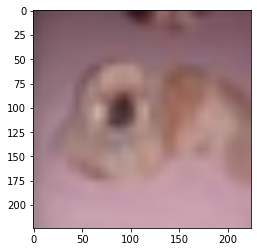

In [30]:
# show images
imshow(torchvision.utils.make_grid(inputs))
# print labels


torch.Size([2048, 7, 7])


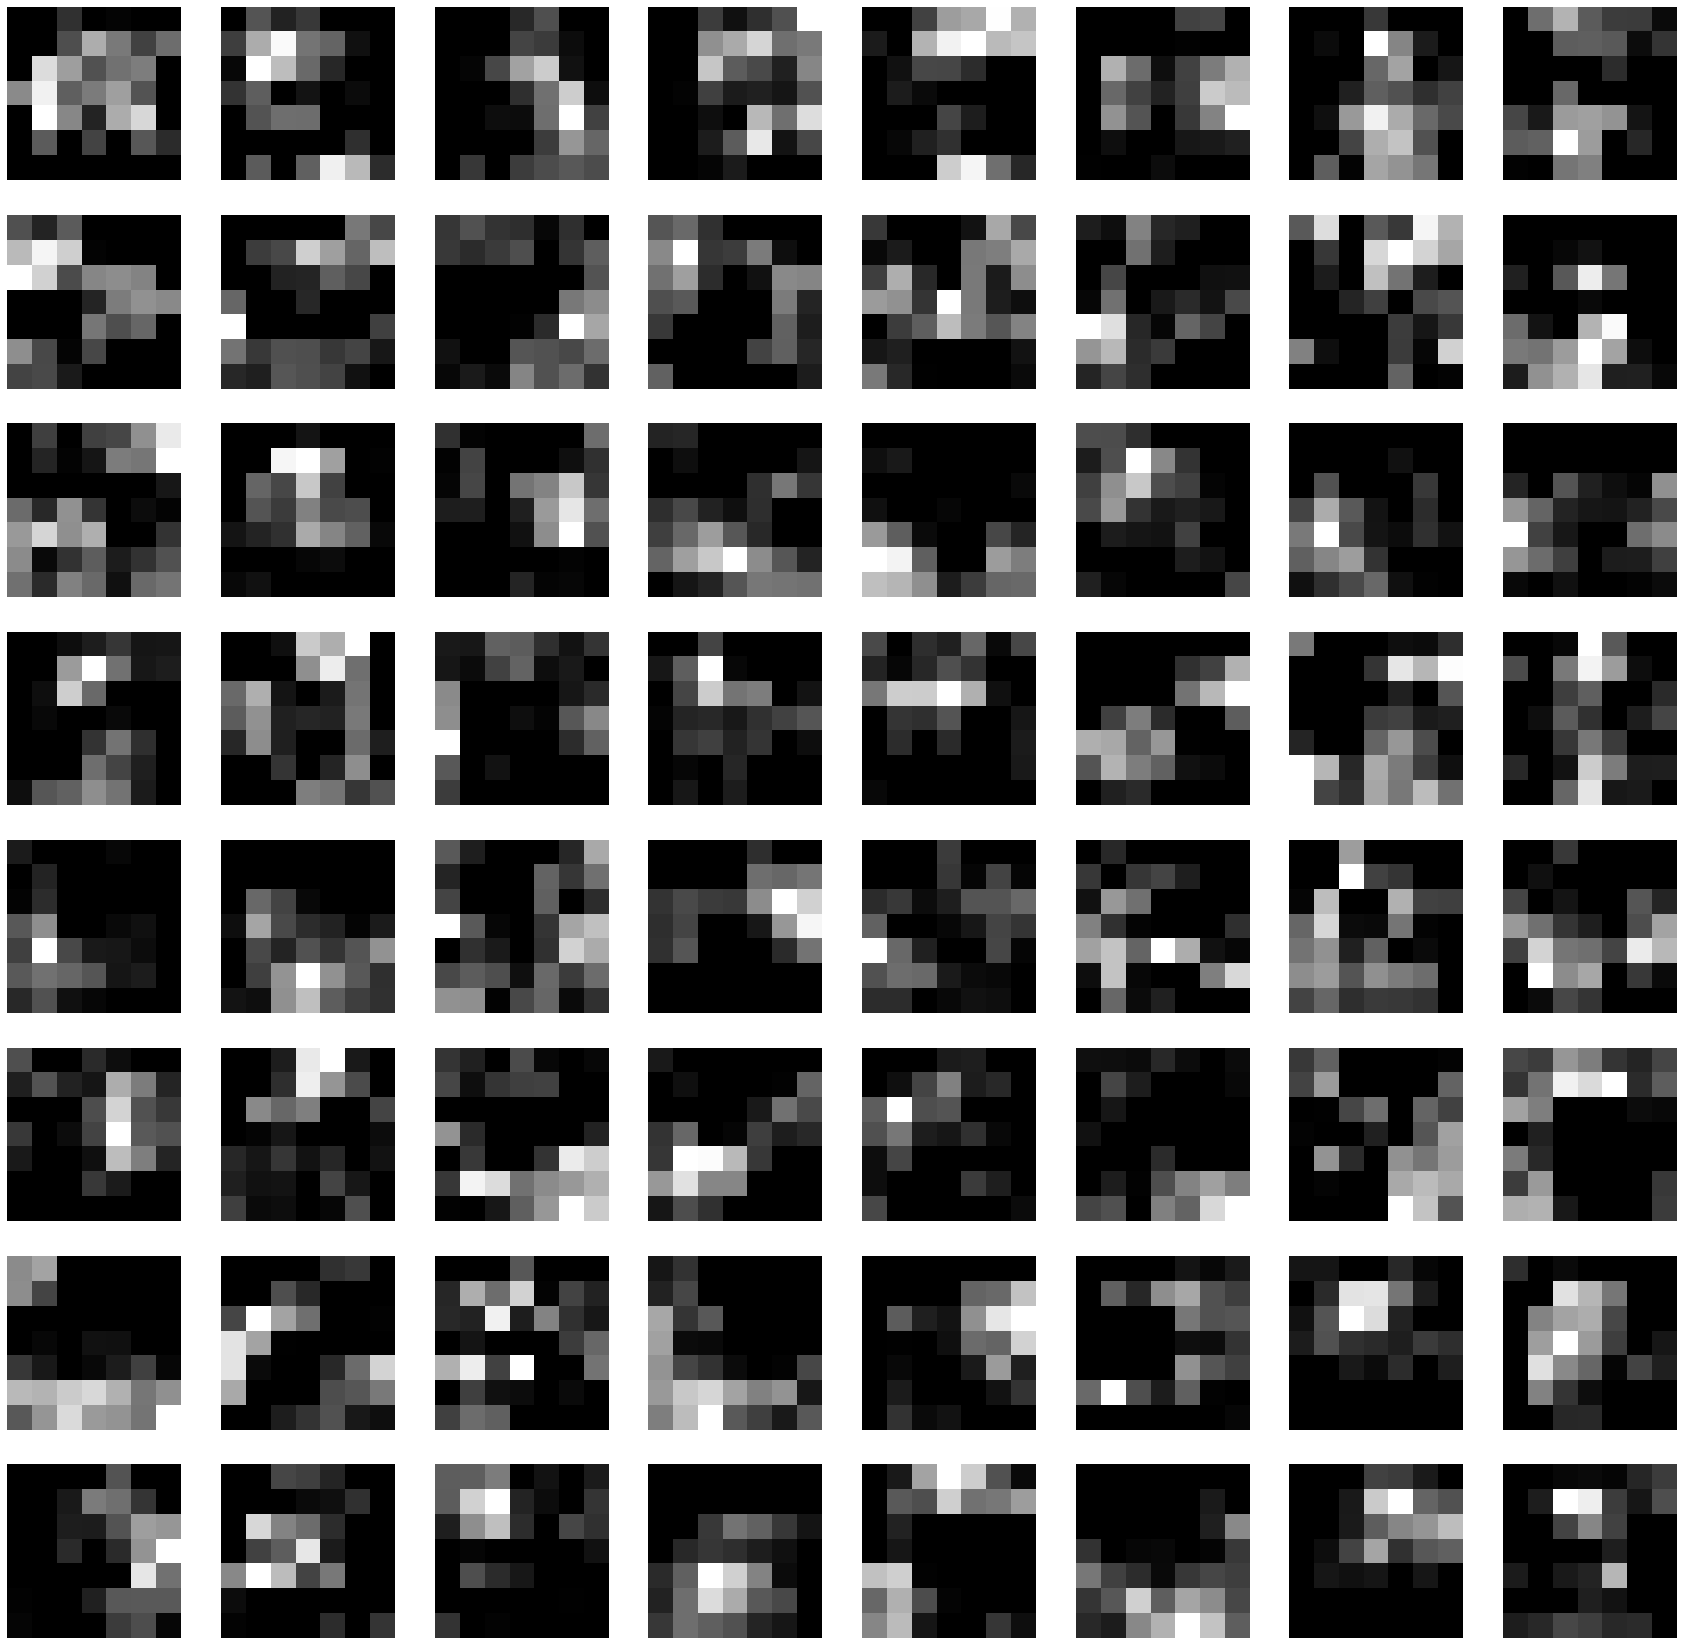

In [33]:
plt.figure(figsize=(30, 30))
layer_viz = output[0, :, :, :]
layer_viz = layer_viz.data
print(layer_viz.size())
for i, filter in enumerate(layer_viz):
    if i == 64: # we will visualize only 8x8 blocks from each layer
        break
    plt.subplot(8, 8, i + 1)
    plt.imshow(filter, cmap='gray')
    plt.axis("off")
plt.show()
plt.close()

In [6]:
new_cifar_model = torch.torch.torch.nn.Sequential(*(list(model.children())[:-2]))

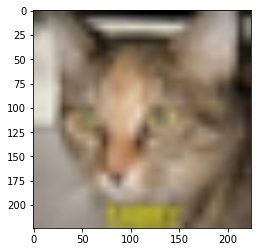

In [16]:
imshow(torchvision.utils.make_grid(inputs))

In [ ]:
plt.figure(figsize=(30, 30))
layer_viz = output[0, :, :, :]
layer_viz = layer_viz.data
print(layer_viz.size())
for i, filter in enumerate(layer_viz):
    if i == 64: # we will visualize only 8x8 blocks from each layer
        break
    plt.subplot(8, 8, i + 1)
    plt.imshow(filter, cmap='gray')
    plt.axis("off")
plt.show()
plt.close()

In [89]:
import torch
from torchvision import transforms
import torch.optim as optim
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import pytorch_lightning as pl
from Models import resnetModule, resnet_cifar10
import seaborn as sns

In [116]:
transform = transforms.Compose([
    # transforms.Pad(4),
    # transforms.RandomCrop(34),
    # transforms.RandomHorizontalFlip(),
    transforms.ToTensor()])

batch_size = 1

dataset = torchvision.datasets.CIFAR10('./datasets/data',train=True, download=True, transform=transform)

trainloader = torch.utils.data.DataLoader(dataset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)


Files already downloaded and verified
torch.Size([1, 3, 32, 32])


torch.Size([1, 3, 32, 32])


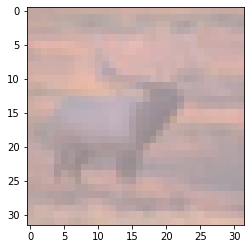

In [120]:
# load image
image, _ = next(iter(trainloader))
print(image.shape)
# show images
imshow(torchvision.utils.make_grid(image))
# print labels

In [133]:
model = resnetModule.ResNetModule.load_from_checkpoint('/Users/lucamelissari/Desktop/MasterThesis/jobs/stats/resnetOfficial_SGD_WD_REL/checkpoints/best-v1.ckpt')
# model = resnetModule.ResNetModule.load_from_checkpoint('/Users/lucamelissari/Desktop/MasterThesis/jobs/stats/resnetOfficial_SGD_WD_REL_ONLY/checkpoints/best.ckpt')
# model = resnetModule.ResNetModule.load_from_checkpoint('/Users/lucamelissari/Desktop/MasterThesis/jobs/stats/resnetOfficialNet_SGD_WD/checkpoints/best.ckpt')

trainer = pl.Trainer()

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs


take cifar 10 official model 
 stampo calss layer <bound method Module.state_dict of Sequential(
  (0): Final_layers()
  (1): Linear(in_features=64, out_features=10, bias=True)
)>


In [134]:
list(list(model.children())[0].children())

[Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False),
 BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True),
 Sequential(
   (0): BasicBlock(
     (conv1): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
     (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
     (conv2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
     (bn2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
     (shortcut): Sequential()
   )
   (1): BasicBlock(
     (conv1): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
     (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
     (conv2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
     (bn2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
     (shortcut)

In [135]:
## GET CONV LAYER FROM MODEL 
# we will save the conv layer weights in this list
model_weights =[]
#we will save the 49 conv layers in this list
conv_layers = []
# get all the model children as list
model_children = list(list(model.children())[0].children()) # baseline model 

#counter to keep count of the conv layers
counter = 0
#append all the conv layers and their respective wights to the list
for i in range(len(model_children)):    
    if type(model_children[i]) == torch.nn.Conv2d:
        counter+=1
        model_weights.append(model_children[i].weight)
        conv_layers.append(model_children[i])
    elif type(model_children[i]) == torch.nn.Sequential:
        for j in range(len(model_children[i])):
            for child in model_children[i][j].children():
                if type(child) == torch.nn.Conv2d:
                    counter+=1
                    model_weights.append(child.weight)
                    conv_layers.append(child)
print(f"Total convolution layers: {counter}")
print("conv_layers")

Total convolution layers: 55
conv_layers


In [136]:
outputs = []
names = []
image_to_process = image
for layer in conv_layers[0:]:
    image_to_process = layer(image_to_process)
    outputs.append(image_to_process)
    names.append(str(layer))
print(len(outputs))
#print feature_maps

55


In [137]:
processed = []
for feature_map in outputs:
    feature_map = feature_map.squeeze(0)
    gray_scale = torch.sum(feature_map,0)
    gray_scale = gray_scale / feature_map.shape[0]
    processed.append(gray_scale.data.cpu().numpy())


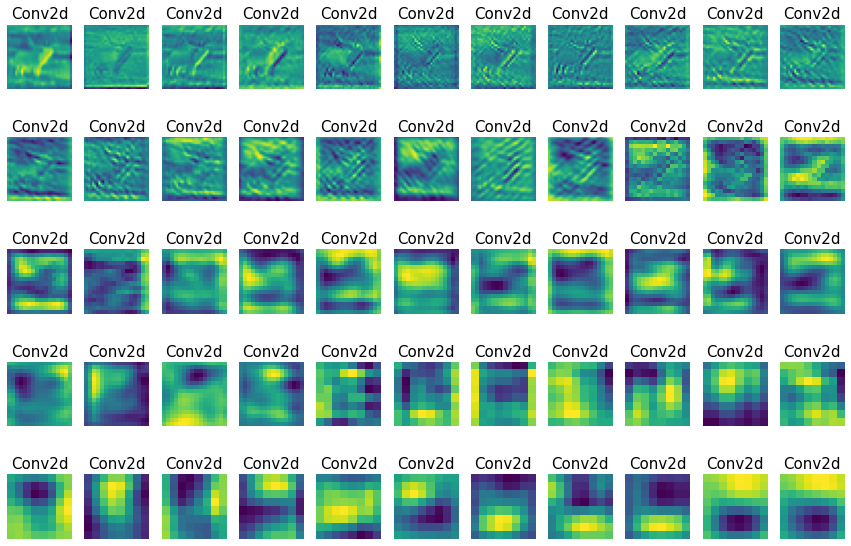

In [138]:
fig = plt.figure(figsize=(15, 10))
for i in range(len(processed)):
    a = fig.add_subplot(5, 11, i+1)
    imgplot = plt.imshow(processed[i])
    a.axis("off")
    a.set_title(names[i].split('(')[0], fontsize=15)
plt.savefig(str('feature_maps.jpg'), bbox_inches='tight')

In [ ]:
print(image.shape)
model_features= torch.nn.Sequential(*(list(model.children())[0]))
model_attention = list(model.children())[1]
x = model_features(image)
print(f'after features layers {x.shape}')
x = model_attention(x)
print(f'after attention layer {x.shape}')

torch.Size([1, 64, 9, 9])


TypeError: torch.nn.modules.container.Sequential() argument after * must be an iterable, not ResNet